# Phase 3 — Exploration

**Question:** on publication day, can we tell which CVEs attackers will exploit within 90 days?

**Leakage rules (CLAUDE.md):** Section 1 uses *global counts only* (CVEs and positives per year) from all data.
Everything after that uses **train only** (published 2022-01-01 → 2024-06-30), because those analyses guide model
choices. `test_locked.parquet` is never opened here.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "mpl"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from features import clean_vendor, vendor_or_cna

FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE = "#2a78d6", "#eb6834"                       # all / not exploited, exploited
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "font.size": 9.5})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

def rate_table(g):
    t = g["label"].agg(cves="size", positives="sum")
    t["rate_%"] = (100 * t["positives"] / t["cves"]).round(2)
    return t

## 1. Global counts: CVEs and exploited CVEs per year (all data)

,cves,positives,rate_%
year,,,
2022,25073,85,0.34
2023,28816,121,0.42
2024,39953,113,0.28
2025,48150,159,0.33
2026,54411,135,0.25


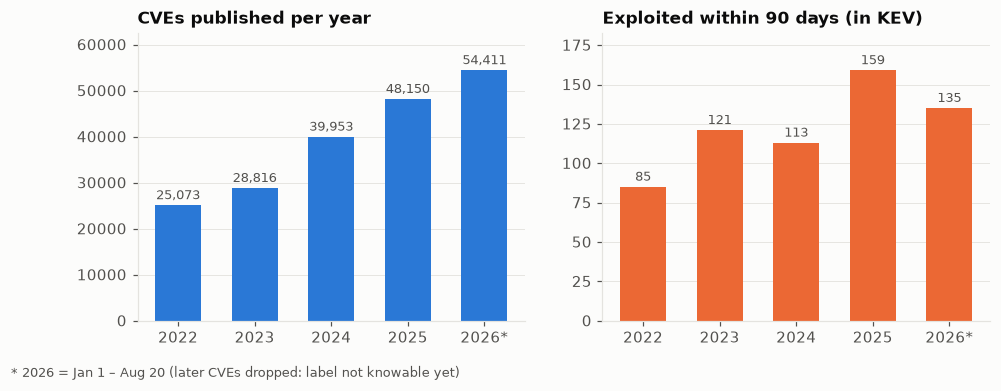

In [2]:
allc = pd.read_parquet(ROOT / "data" / "cve_dataset.parquet", columns=["published", "label"])
by_year = rate_table(allc.groupby(allc["published"].dt.year.rename("year")))
display(by_year)
by_year.to_csv(TAB / "03_positives_by_year.csv")

yrs = by_year.index.astype(str).tolist(); yrs[-1] += "*"
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a, col, color, title in [(ax[0], "cves", BLUE, "CVEs published per year"),
                             (ax[1], "positives", ORANGE, "Exploited within 90 days (in KEV)")]:
    a.bar(yrs, by_year[col], color=color, width=0.6)
    for x, v in zip(yrs, by_year[col]):
        a.annotate(f"{v:,}", (x, v), ha="center", va="bottom", fontsize=8.5, color=INK2, xytext=(0, 2), textcoords="offset points")
    a.set_title(title, loc="left"); a.grid(axis="x", visible=False); a.set_ylim(0, by_year[col].max() * 1.15)
fig.text(0.01, -0.04, "* 2026 = Jan 1 – Aug 20 (later CVEs dropped: label not knowable yet)", color=INK2, fontsize=8.5)
save(fig, "03_01_cves_and_positives_per_year")
del allc

## 2. Train set (everything below uses train only)

In [3]:
dev = pd.read_parquet(ROOT / "data" / "dev.parquet")
train = dev[dev["split"] == "train"].copy()
del dev
assert train["published"].max() < pd.Timestamp("2024-07-01")
print(f"train: {len(train):,} CVEs, {int(train['label'].sum())} positives ({train['label'].mean():.3%}), "
      f"{train['published'].min().date()} -> {train['published'].max().date()}")

train: 74,268 CVEs, 251 positives (0.338%), 2022-01-01 -> 2024-06-30


## 3. Clean vendor names
Rule (in `src/features.py`, shared with the models): lowercase, punctuation → space, drop company suffixes
(Inc, LLC, Corp, Systems, SE, …). Missing / "n/a" vendor → fall back to the CNA, like `cv_group`.

In [4]:
train["vendor_clean"] = clean_vendor(train["vendor"])
train["vendor_key"] = vendor_or_cna(train)
print(f"unique vendor spellings (raw): {train['vendor'].nunique():,}  ->  after cleaning: {train['vendor_clean'].nunique():,}")
print(f"vendor missing or n/a: {train['vendor_clean'].isna().mean():.1%} of train CVEs (fallback = CNA)")
merged = (train.dropna(subset=["vendor_clean"]).groupby("vendor_clean")["vendor"]
          .agg(n="size", spellings=lambda s: sorted(s.unique())))
merged = merged[merged["spellings"].map(len) > 1].sort_values("n", ascending=False)
print(f"vendors whose spellings were merged: {len(merged)}; biggest:")
display(merged.head(10))

unique vendor spellings (raw): 7,457  ->  after cleaning: 6,996
vendor missing or n/a: 33.2% of train CVEs (fallback = CNA)
vendors whose spellings were merged: 414; biggest:


,n,spellings
vendor_clean,,
microsoft,2398,"[Microsoft, microsoft]"
linux,2358,"[Linux, linux]"
google,1326,"[Google, Google LLC, google]"
sourcecodester,973,"[SourceCodester, Sourcecodester]"
siemens,689,"[Siemens, siemens]"
cisco,681,"[Cisco, Cisco Systems, Inc., cisco]"
jenkins project,668,"[Jenkins Project, Jenkins project]"
mozilla,474,"[Mozilla, mozilla]"
sap,418,"[SAP, SAP SE, SAP_SE]"


## 4. Exploitation rate by vendor

vendors in train: 7,074; vendors with >= 1 exploited CVE: 54
top 10 vendors hold 70% of exploited CVEs but only 33% of all CVEs
vendors with zero exploited CVEs account for 53% of CVEs


,cves,positives,rate_%
vendor_key,,,
microsoft,2398,49,2.04
apple,1099,32,2.91
google,1326,26,1.96
cna:cve@mitre.org,17120,25,0.15
cisco,681,12,1.76
fortinet,363,7,1.93
adobe,1479,6,0.41
cna:security@vmware.com,188,6,3.19
ivanti,129,6,4.65


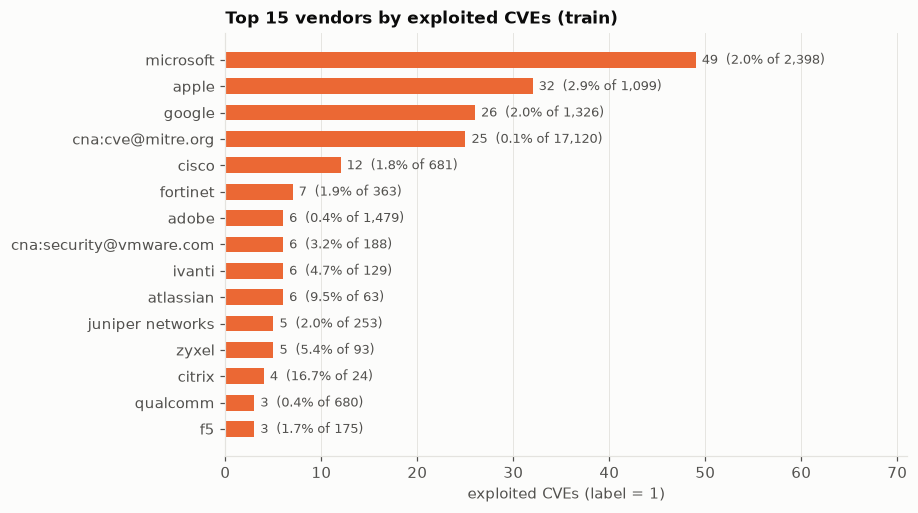

In [5]:
vend = rate_table(train.groupby("vendor_key")).sort_values(["positives", "cves"], ascending=False)
vend.to_csv(TAB / "03_train_label_rate_by_vendor.csv")
n_pos = int(train["label"].sum())
vend_pos = vend[vend["positives"] > 0]
top10 = vend.head(10)
print(f"vendors in train: {len(vend):,}; vendors with >= 1 exploited CVE: {len(vend_pos)}")
print(f"top 10 vendors hold {top10['positives'].sum() / n_pos:.0%} of exploited CVEs but only "
      f"{top10['cves'].sum() / len(train):.0%} of all CVEs")
print(f"vendors with zero exploited CVEs account for {vend.loc[vend['positives'] == 0, 'cves'].sum() / len(train):.0%} of CVEs")
display(vend.head(15))

top = vend.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top["positives"], color=ORANGE, height=0.6)
for y, (p, r, n) in enumerate(zip(top["positives"], top["rate_%"], top["cves"])):
    ax.annotate(f"{p}  ({r:.1f}% of {n:,})", (p, y), va="center", fontsize=8.5, color=INK2, xytext=(4, 0), textcoords="offset points")
ax.set_title("Top 15 vendors by exploited CVEs (train)", loc="left"); ax.set_xlabel("exploited CVEs (label = 1)")
ax.grid(axis="y", visible=False); ax.set_xlim(0, top["positives"].max() * 1.45)
save(fig, "03_02_vendors_top15")

## 5. Exploitation rate by CWE (weakness type) — CNA-assigned CWE only (day-0)

CWEs in train: 583; with >= 1 exploited CVE: 46


,cves,positives,rate_%
cwe,,,
NVD-CWE-noinfo,34770,141,0.41
CWE-20,1434,8,0.56
CWE-416,903,7,0.78
CWE-284,902,6,0.67
CWE-78,810,6,0.74
CWE-122,609,6,0.99
CWE-94,386,6,1.55
CWE-121,888,5,0.56
CWE-288,97,5,5.15


Highest rates among CWEs with >= 200 CVEs:


,cves,positives,rate_%
cwe,,,
CWE-306,243,4,1.65
CWE-94,386,6,1.55
CWE-122,609,6,0.99
CWE-502,470,4,0.85
CWE-416,903,7,0.78
CWE-78,810,6,0.74
CWE-119,437,3,0.69
CWE-284,902,6,0.67


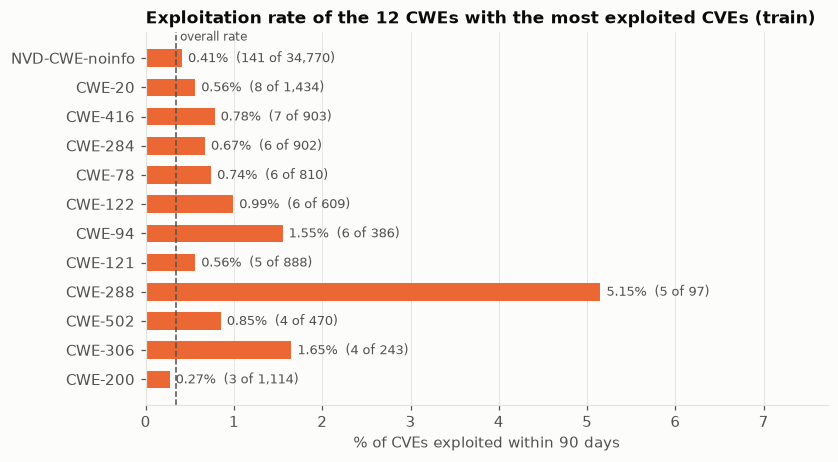

In [6]:
cwe = rate_table(train.groupby("cwe")).sort_values(["positives", "cves"], ascending=False)
cwe.to_csv(TAB / "03_train_label_rate_by_cwe.csv")
print(f"CWEs in train: {len(cwe)}; with >= 1 exploited CVE: {(cwe['positives'] > 0).sum()}")
display(cwe.head(15))
print("Highest rates among CWEs with >= 200 CVEs:")
display(cwe[cwe["cves"] >= 200].sort_values("rate_%", ascending=False).head(8))

top = cwe.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(top.index, top["rate_%"], color=ORANGE, height=0.6)
for y, (p, r, n) in enumerate(zip(top["positives"], top["rate_%"], top["cves"])):
    ax.annotate(f"{r:.2f}%  ({p} of {n:,})", (r, y), va="center", fontsize=8.5, color=INK2, xytext=(4, 0), textcoords="offset points")
ax.axvline(100 * train["label"].mean(), color=INK2, lw=1, ls="--")
ax.annotate("overall rate", (100 * train["label"].mean(), 11.6), fontsize=8, color=INK2, xytext=(3, 0), textcoords="offset points")
ax.set_title("Exploitation rate of the 12 CWEs with the most exploited CVEs (train)", loc="left")
ax.set_xlabel("% of CVEs exploited within 90 days"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, top["rate_%"].max() * 1.5)
save(fig, "03_03_cwe_top12_rate")

## 6. CVSS score: exploited vs not exploited (day-0 = CNA score only)
Decision 9: only the CNA's own score exists on publication day. Third-party CISA-ADP scores were mostly added
later, to exploited CVEs, so the "fallback" score (CNA > CISA-ADP > NVD) is shown only as a *generous* comparison.

CNA gave no CVSS score: 43.7% of train CVEs | positives 42.6% | negatives 43.7%
                 count  mean   std  min  25%  50%  75%   max
label                                                       
not exploited  41670.0  6.54  1.74  0.0  5.4  6.5  7.8  10.0
exploited        144.0  8.23  1.65  3.3  7.5  8.4  9.8  10.0
Day-0 (CNA score):


,cves,positives,rate_%,share_of_exploited_%
cvss band,,,,
0–3.9,3018,3,0.10,1.2
4–6.9,20432,23,0.11,9.2
7–8.9,15084,63,0.42,25.1
9–10,3280,55,1.68,21.9
no score,32454,107,0.33,42.6


Generous (fallback score):


,cves,positives,rate_%,share_of_exploited_%
cvss band,,,,
0–3.9,3444,4,0.12,1.6
4–6.9,34792,33,0.09,13.1
7–8.9,26862,126,0.47,50.2
9–10,9162,88,0.96,35.1
no score,8,0,0.00,0.0


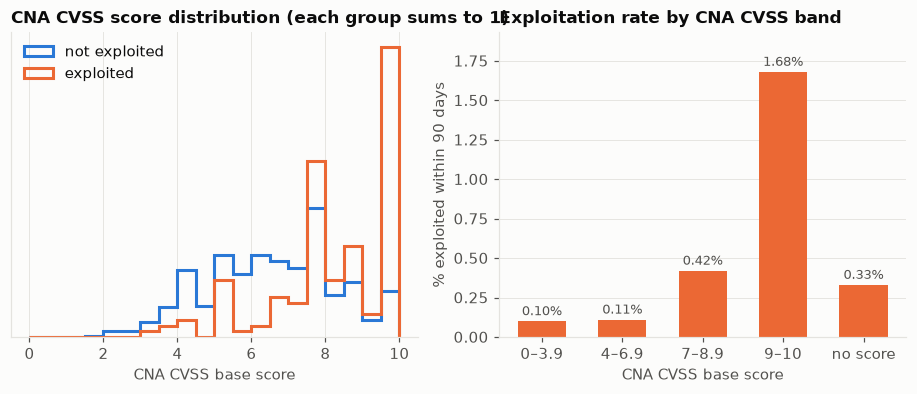

In [7]:
print(f"CNA gave no CVSS score: {train['cvss_cna_score'].isna().mean():.1%} of train CVEs | "
      f"positives {train.loc[train['label'] == 1, 'cvss_cna_score'].isna().mean():.1%} | "
      f"negatives {train.loc[train['label'] == 0, 'cvss_cna_score'].isna().mean():.1%}")
s = train.dropna(subset=["cvss_cna_score"])
print(s.groupby("label")["cvss_cna_score"].describe().round(2).rename(index={0: "not exploited", 1: "exploited"}))
edges, labels = [0, 4, 7, 9, 10.01], ["0–3.9", "4–6.9", "7–8.9", "9–10"]
def band_table(score):
    b = pd.cut(score, edges, right=False, labels=labels).cat.add_categories("no score").fillna("no score")
    t = rate_table(train.groupby(b, observed=False)); t.index.name = "cvss band"
    t["share_of_exploited_%"] = (100 * t["positives"] / n_pos).round(1)
    return t
band = band_table(train["cvss_cna_score"]); band_fb = band_table(train["cvss_score"])
print("Day-0 (CNA score):"); display(band)
print("Generous (fallback score):"); display(band_fb)
band.to_csv(TAB / "03_train_rate_by_cvss_band_cna.csv"); band_fb.to_csv(TAB / "03_train_rate_by_cvss_band_fallback.csv")

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
bins = np.arange(0, 10.5, 0.5)
for lab, color, name in [(0, BLUE, "not exploited"), (1, ORANGE, "exploited")]:
    ax[0].hist(s.loc[s["label"] == lab, "cvss_cna_score"], bins=bins, density=True, histtype="step", lw=2, color=color, label=name)
ax[0].set_title("CNA CVSS score distribution (each group sums to 1)", loc="left"); ax[0].set_xlabel("CNA CVSS base score")
ax[0].legend(frameon=False); ax[0].set_yticks([])
ax[1].bar(band.index.astype(str), band["rate_%"], color=ORANGE, width=0.6)
for x, r in zip(band.index.astype(str), band["rate_%"]):
    ax[1].annotate(f"{r:.2f}%", (x, r), ha="center", va="bottom", fontsize=8.5, color=INK2, xytext=(0, 2), textcoords="offset points")
ax[1].set_title("Exploitation rate by CNA CVSS band", loc="left"); ax[1].set_xlabel("CNA CVSS base score")
ax[1].set_ylabel("% exploited within 90 days"); ax[1].set_ylim(0, band["rate_%"].max() * 1.15); ax[1].grid(axis="x", visible=False)
save(fig, "03_04_cvss_exploited_vs_not")

## 7. What the current rule (CVSS ≥ 9) catches and misses — train
**Day-0** = the CNA score only (CVEs without one are not patched): what the team could actually do on publication day.
**Generous** = fallback score incl. later CISA-ADP / NVD scores: an upper bound that uses hindsight.
(Phase 4 repeats this on val; Phase 6 reports both.)

In [8]:
months = (train["published"].max() - train["published"].min()).days / 30.44
rows = []
for thr in (9, 7):
    for kind, score in [("day-0 (CNA only)", train["cvss_cna_score"]), ("generous (fallback)", train["cvss_score"])]:
        flag = score >= thr
        tp = int((flag & (train["label"] == 1)).sum())
        rows.append({"rule": f"CVSS >= {thr}", "score": kind, "patches": int(flag.sum()),
                     "patches_per_month": round(flag.sum() / months), "exploited_caught": tp,
                     "exploited_missed": n_pos - tp, "recall_%": round(100 * tp / n_pos, 1),
                     "precision_%": round(100 * tp / flag.sum(), 2)})
rules = pd.DataFrame(rows).set_index(["rule", "score"]); display(rules)
rules.to_csv(TAB / "03_train_cvss_rules.csv")
missed = train[(train["label"] == 1) & ~(train["cvss_cna_score"] >= 9)]
print(f"exploited CVEs missed by day-0 CVSS >= 9: {len(missed)} of {n_pos}. Their CNA CVSS bands:")
print(pd.cut(missed["cvss_cna_score"], edges, right=False, labels=labels).cat.add_categories("no CNA score")
      .fillna("no CNA score").value_counts(sort=False).to_string())
print("\nTop vendors among the missed ones:")
print(missed["vendor_key"].value_counts().head(8).to_string())

patches  patches_per_month  exploited_caught  exploited_missed  recall_%  precision_%
rule      score                                                                                                     
CVSS >= 9 day-0 (CNA only)        3280                110                55               196      21.9         1.68
          generous (fallback)     9162                306                88               163      35.1         0.96
CVSS >= 7 day-0 (CNA only)       18364                614               118               133      47.0         0.64
          generous (fallback)    36024               1204               214                37      85.3         0.59

exploited CVEs missed by day-0 CVSS >= 9: 196 of 251. Their CNA CVSS bands:
cvss_cna_score
0–3.9             3
4–6.9            23
7–8.9            63
9–10              0
no CNA score    107

Top vendors among the missed ones:
vendor_key
microsoft                  47
apple                      32
google                     26
cna:cve@mitre.org          23
cna:security@vmware.com     6
cisco                       6
adobe                       4
ivanti                      4


## 8. Where CVSS scores come from — the leakage check behind Decision 9
cna = the CVE's own publisher (day-0); CISA-ADP = CISA's third-party enrichment; nvd = NVD analysts. The ADP and
NVD scores are added after publication. **Analysis only — none of these columns is a model feature.**

In [9]:
src_t = rate_table(train.groupby(train["cvss_source"].replace({"other": "cisa-adp (other)"})))
src_t["share_of_exploited_%"] = (100 * src_t["positives"] / n_pos).round(1)
display(src_t); src_t.to_csv(TAB / "03_train_cvss_source.csv")
q = train.groupby(train["published"].dt.to_period("Q"))
adp = pd.DataFrame({"all CVEs with ADP score %": (100 * q["has_adp_cvss"].mean()).round(1),
                    "exploited CVEs with ADP score %": (100 * train[train["label"] == 1]
                        .groupby(train["published"].dt.to_period("Q"))["has_adp_cvss"].mean()).round(0)})
print("CISA-ADP did not exist in 2022, yet many 2022 exploited CVEs carry an ADP score -> added in hindsight:")
display(adp)

,cves,positives,rate_%,share_of_exploited_%
cvss_source,,,,
cisa-adp (other),15267,107,0.70,42.6
cna,41814,144,0.34,57.4
none,8,0,0.00,0.0
nvd,17179,0,0.00,0.0


CISA-ADP did not exist in 2022, yet many 2022 exploited CVEs carry an ADP score -> added in hindsight:


,all CVEs with ADP score %,exploited CVEs with ADP score %
published,,
2022Q1,3.4,46.0
2022Q2,2.0,50.0
2022Q3,11.7,76.0
2022Q4,48.3,35.0
2023Q1,34.5,48.0
2023Q2,35.1,56.0
2023Q3,5.6,37.0
2023Q4,9.2,30.0
2024Q1,31.3,26.0


## 9. How fast do CVEs reach KEV? (`days_to_kev`, train CVEs ever in KEV)
Negative = in KEV before NVD published it. Label = 1 only up to 90 days.

train CVEs ever in KEV: 368; labelled positive (<= 90 d): 251; added later (label 0): 117
  in KEV within   0 days of publication: 28%
  in KEV within   7 days of publication: 47%
  in KEV within  30 days of publication: 58%
  in KEV within  90 days of publication: 68%
  in KEV within 365 days of publication: 87%
  median days to KEV: 12


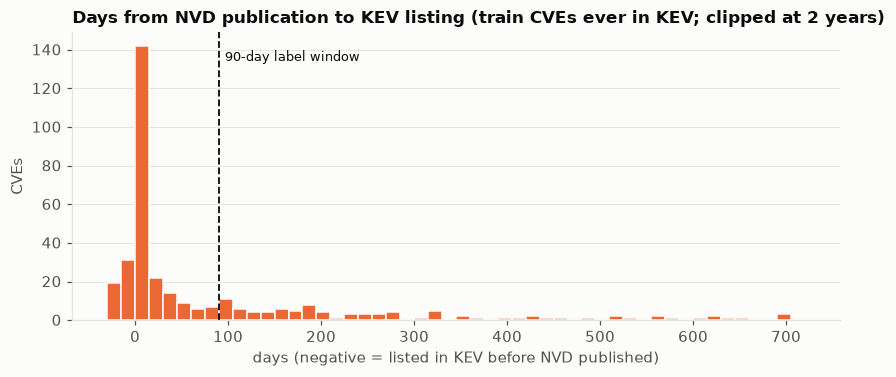

In [10]:
k = train.loc[train["in_kev_ever"], "days_to_kev"]
print(f"train CVEs ever in KEV: {len(k)}; labelled positive (<= 90 d): {(k <= 90).sum()}; added later (label 0): {(k > 90).sum()}")
for d in (0, 7, 30, 90, 365):
    print(f"  in KEV within {d:>3} days of publication: {(k <= d).mean():.0%}")
print(f"  median days to KEV: {k.median():.0f}")

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(k.clip(-30, 730), bins=np.arange(-30, 735, 15), color=ORANGE, edgecolor=SURF, linewidth=1)
ax.axvline(90, color=INK, lw=1.2, ls="--")
ax.annotate("90-day label window", (90, ax.get_ylim()[1] * 0.9), fontsize=8.5, color=INK, xytext=(4, 0), textcoords="offset points")
ax.set_title("Days from NVD publication to KEV listing (train CVEs ever in KEV; clipped at 2 years)", loc="left")
ax.set_xlabel("days (negative = listed in KEV before NVD published)"); ax.set_ylabel("CVEs"); ax.grid(axis="x", visible=False)
save(fig, "03_05_days_to_kev")

## 10. Summary for the “problem” slide

In [11]:
def rule(thr, kind):
    r = rules.loc[(f"CVSS >= {thr}", kind)]
    return int(r["patches_per_month"]), r["recall_%"], r["precision_%"], int(r["exploited_missed"])
pm, rc, pr, ms = rule(9, "day-0 (CNA only)"); gpm, grc, _, _ = rule(9, "generous (fallback)")
print(f"""- CVE volume roughly doubled 2022 -> 2025 ({by_year.loc[2022, 'cves']:,} -> {by_year.loc[2025, 'cves']:,}); exploited CVEs stayed ~{int(by_year['positives'].iloc[:-1].mean())}/year.
- Only {train['label'].mean():.2%} of train CVEs were exploited within 90 days (1 in {round(1 / train['label'].mean())}).
- Current rule CVSS >= 9, day-0 (CNA score): {pm} emergency patches/month, catches only {rc}% of exploited CVEs
  (precision {pr}%) -> misses {ms} of {n_pos}. {train['cvss_cna_score'].isna().mean():.0%} of CVEs have no CNA score at all.
  (Generous version with later CISA-ADP/NVD scores: {gpm}/month, {grc}% - an upper bound that uses hindsight.)
- Exploitation is concentrated: top 10 vendors = {top10['positives'].sum() / n_pos:.0%} of exploited CVEs vs {top10['cves'].sum() / len(train):.0%} of all CVEs.
- Speed: {(k <= 0).mean():.0%} of KEV CVEs are listed by publication day, {(k <= 30).mean():.0%} within 30 days -> a day-0 prediction is needed.""")

- CVE volume roughly doubled 2022 -> 2025 (25,073 -> 48,150); exploited CVEs stayed ~119/year.
- Only 0.34% of train CVEs were exploited within 90 days (1 in 296).
- Current rule CVSS >= 9, day-0 (CNA score): 110 emergency patches/month, catches only 21.9% of exploited CVEs
  (precision 1.68%) -> misses 196 of 251. 44% of CVEs have no CNA score at all.
  (Generous version with later CISA-ADP/NVD scores: 306/month, 35.1% - an upper bound that uses hindsight.)
- Exploitation is concentrated: top 10 vendors = 70% of exploited CVEs vs 33% of all CVEs.
- Speed: 28% of KEV CVEs are listed by publication day, 58% within 30 days -> a day-0 prediction is needed.
